# 13 — Models per regime: GP, ensembles, intervals, and the noise floor

`scripts/regime_phase2.py`, robust preparation and the robust EMA level. Base models, pooled per regime, predicting
the jitter: ridge, XGBoost, GRU (16 shots), ridge + GRU (the GRU learns the ridge's residual), and a sparse
variational GP (GPyTorch, ARD RBF kernel, 256 inducing points). Ensembles: the equal-weight mean, and non-negative
stacking weights fitted on the validation block. Intervals: the GP's own, and split-conformal around the stack.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

segment,0,3,4,5,1,6,7
model,,,,,,,
level_only,7.28,9.50,11.09,2.49,3.03,2.16,3.87
ridge,3.83,6.89,8.25,0.99,1.12,0.72,2.48
xgboost,3.92,6.93,8.02,1.26,1.30,0.87,2.56
gru,3.82,6.98,8.14,0.95,1.03,0.68,2.47
ridge+gru,3.82,6.88,8.24,0.95,1.01,0.68,2.54
gp,3.84,6.96,8.02,0.98,1.07,0.70,2.47
mean_ensemble,3.81,6.88,8.09,0.97,1.05,0.70,2.46
stack_nnls,3.81,6.91,8.06,1.15,1.22,0.82,2.45


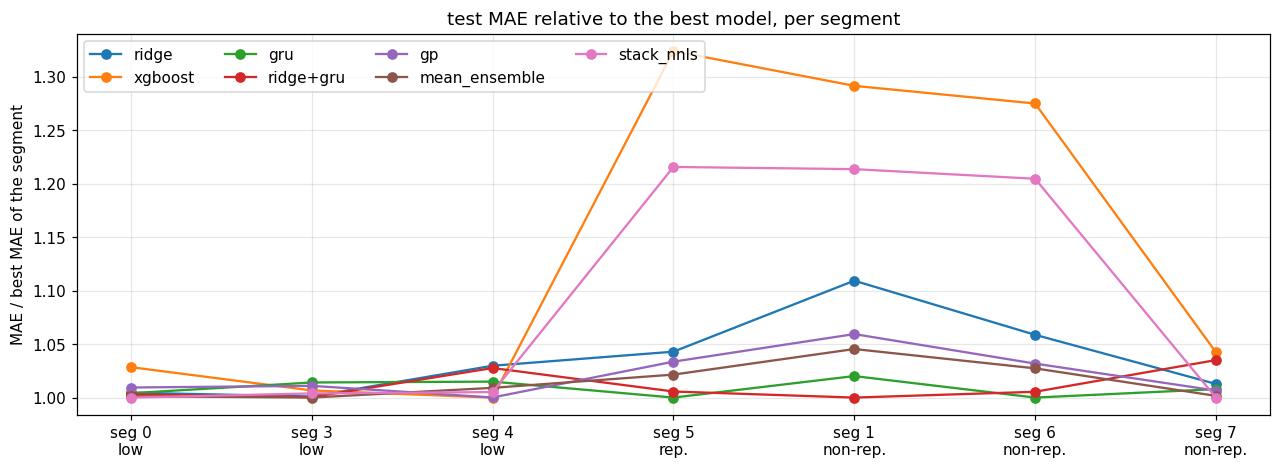

In [2]:
p2 = pd.read_csv(R / "phase2/scores.csv")
info = json.loads((R / "phase2/info.json").read_text())
order = ["level_only", "ridge", "xgboost", "gru", "ridge+gru", "gp", "mean_ensemble", "stack_nnls"]
tab = p2.pivot_table(index="model", columns="segment", values="mae_pct").loc[order, SEG_ORDER]
fig, ax = plt.subplots(figsize=(14, 4.5))
norm = tab.drop("level_only") / tab.drop("level_only").min()
for i, mname in enumerate(norm.index):
    ax.plot(range(len(SEG_ORDER)), norm.loc[mname], "o-", label=mname)
ax.set_xticks(range(len(SEG_ORDER)), [f"seg {s}\n{segs_reg}" for s, segs_reg in zip(SEG_ORDER, ["low"] * 3 + ["rep."] + ["non-rep."] * 3)])
ax.set_ylabel("MAE / best MAE of the segment"); ax.legend(ncol=4); ax.set_title("test MAE relative to the best model, per segment")
tab.round(2)

**Reading.**
- No single family wins everywhere: ridge + GRU on seg 1, GRU on segs 5 and 6, GP on seg 4, the equal mean on
  segs 0 and 3. The spread between the top models is a few percent.
- **The equal-weight mean is as good as the best single model in every regime** and is the safe choice.
- Stacking with weights fitted on the validation block is *worse* at high charge. Its weights sum to less than 1
  (it shrinks towards the level), because the validation block drifts relative to the test block.

In [3]:
w = pd.DataFrame({r: v["stack_weights"] for r, v in info.items()}).round(2)
ls = pd.DataFrame({r: v["gp_lengthscales"] for r, v in info.items()}).round(2)
display(w); display(ls.sort_values("high_rep"))

,low,high_rep,high_nonrep
ridge,0.29,0.00,0.00
xgboost,0.00,0.00,0.00
gru,0.16,0.73,0.37
ridge+gru,0.00,0.00,0.43
gp,0.56,0.00,0.00


,low,high_rep,high_nonrep
camera_spike,2.16,2.95,2.37
SVD_s1,3.40,2.98,3.48
BTV_intensity,2.84,3.20,2.88
missing,2.55,3.37,4.21
PGLA_drop,3.26,3.59,3.97
PKI15A,3.35,3.61,3.98
SVD_s6,3.49,3.66,4.39
BTV_mean_x,3.48,3.75,4.04
SVD_s5,3.31,3.76,4.03
lab_laser_power,3.18,3.80,3.83


The GP's ARD lengthscales (inputs standardised and clipped at ±5) are all of order 3: no input is switched off, and
the ranking is mild — the camera group (spike flag, intensity, SVD s1) and the lab meter come first. The GP is a
competitive jitter model but not a selective one here.

## How far from the floor?

No model can predict the BCM's own measurement noise. `scripts/bcm_noise_floor.py` estimated it with a three-cornered
hat (BCM, camera, laser). Below: the residual rms of each model divided by that floor (1 = at the floor).

segment,0,3,4,5,1,6
model,,,,,,
level_only,1.93,1.49,1.34,4.46,3.23,3.49
ridge,1.09,1.25,1.08,2.29,1.60,1.38
xgboost,1.10,1.26,1.05,2.51,1.70,1.50
gru,1.07,1.26,1.06,2.25,1.55,1.23
ridge+gru,1.09,1.25,1.09,2.27,1.53,1.27
gp,1.10,1.25,1.05,2.31,1.58,1.21
mean_ensemble,1.08,1.25,1.06,2.25,1.55,1.26
stack_nnls,1.08,1.25,1.05,2.37,1.61,1.44


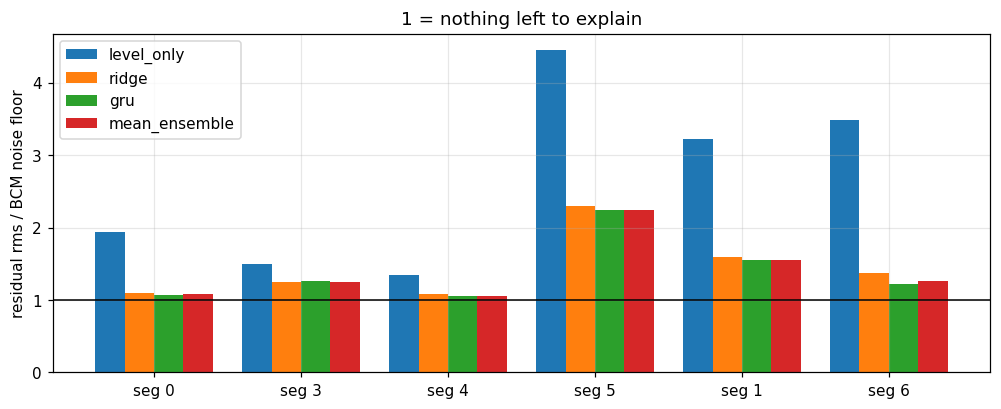

In [4]:
gap = p2.pivot_table(index="model", columns="segment", values="gap_to_floor").loc[order]
gap = gap[[s for s in SEG_ORDER if s in gap.columns]]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(gap.shape[1])
for k, mname in enumerate(["level_only", "ridge", "gru", "mean_ensemble"]):
    ax.bar(x + (k - 1.5) * 0.2, gap.loc[mname], 0.2, label=mname)
ax.axhline(1, color="k", lw=1); ax.set_xticks(x, [f"seg {s}" for s in gap.columns])
ax.set_ylabel("residual rms / BCM noise floor"); ax.legend(); ax.set_title("1 = nothing left to explain")
gap.round(2)

**Reading.** Low charge (segs 0, 3, 4) is at 1.05–1.25 × the floor: about half the BCM jitter there is the BCM's own
noise, and the models have taken the rest. Seg 6 is at 1.2, seg 1 at 1.5, and **seg 5 at 2.25: the repetitive regime
has the most room left**. Seg 7's test region is dominated by its final jump to 18 nC (jitter explained ≈ 0.1 for
every model) and has no floor estimate.

## Intervals

90 % intervals on the test shots: coverage (target 0.90) and mean width in % of the level.

In [5]:
cov = p2[p2.model.isin(["gp", "stack_nnls"])].pivot_table(index="model", columns="segment", values=["cover90", "width90_pct"])
cov.round(3)

cover90                                           width90_pct  \
segment          0      1      3      4      5      6      7           0   
model                                                                      
gp           0.985  0.916  0.891  0.839  0.942  0.990  0.864      30.877   
stack_nnls   0.985  0.953  0.861  0.790  0.975  0.993  0.938      28.364   

                                                        
segment         1       3       4      5      6      7  
model                                                   
gp          5.380  31.018  30.981  5.763  5.381  5.435  
stack_nnls  7.954  28.364  28.364  8.941  7.954  7.954

**Reading.** Coverage is 79–99 %: too wide at high charge (≥ 94 %) and too narrow on the low-charge segments 3 and 4
(79–89 %). Both intervals have one width per regime, while the jitter's size changes from segment to segment and
shot to shot. Next: a heteroscedastic noise model (GP with a learned noise function, or conformal intervals scaled by
a rolling jitter estimate, as `forecast_uncertainty.py` does with its rolling calibration).

## One test region, seen shot by shot

Ridge on the jitter, refitted here (seconds on a CPU), on seg 5's test region.

n                   1979.000
level_nC               5.877
mae_nC                 0.058
mae_pct                0.990
r2                     0.870
jitter_rms_pct         3.210
resid_rms_pct          1.651
jitter_explained       0.735
slow_share             0.018
dtype: float64

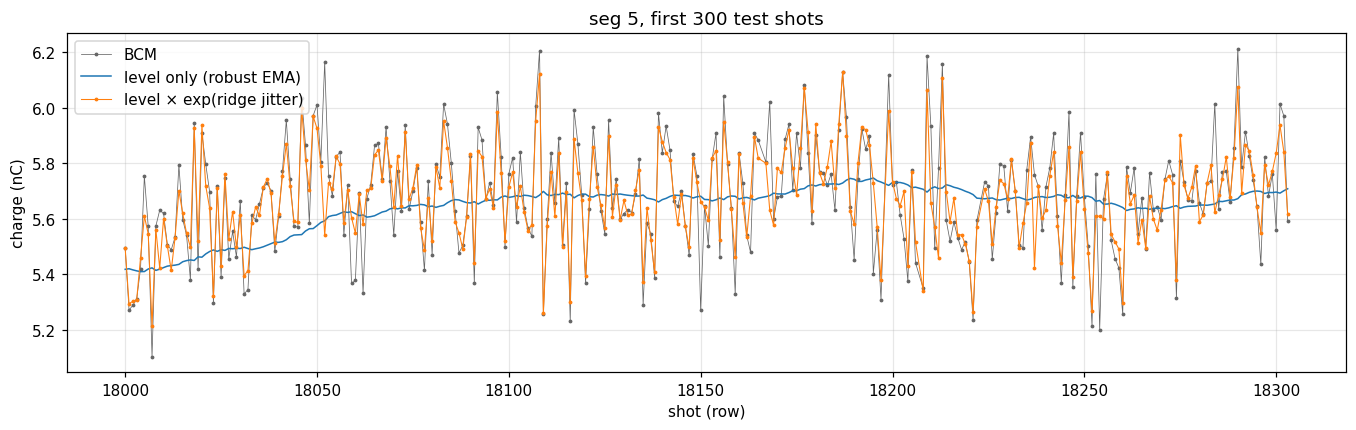

In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from decompose import causal, f_robust_ema
segs, names = load(R.parent / "results/datasets", robust=5, fast_filter=causal(lambda x: f_robust_ema(x, 25)))
G = [segs[s] for s in REGIMES["high_rep"]]
X = np.concatenate([np.c_[g["Xfast"], g["missing"]] for g in G]); t = np.nan_to_num(np.concatenate([g["jitter"] for g in G]))
fit = np.concatenate([g["fit"] for g in G])
m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))).fit(X[fit], t[fit])
g = segs[5]; p = np.exp(g["level"] + m.predict(np.c_[g["Xfast"], g["missing"]]))
te = np.flatnonzero(g["test"])[:300]
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(te, g["y"][te], ".-", ms=3, lw=0.5, color="0.4", label="BCM")
ax.plot(te, np.exp(g["level"][te]), lw=1, label="level only (robust EMA)")
ax.plot(te, p[te], ".-", ms=3, lw=0.7, label="level × exp(ridge jitter)")
ax.set_xlabel("shot (row)"); ax.set_ylabel("charge (nC)"); ax.legend(); ax.set_title("seg 5, first 300 test shots")
pd.Series(score(g, p)).round(3)